<a href="https://colab.research.google.com/github/Mushtaq-noor/Assignment-03-web-programming/blob/main/BeautifulSoup_Book_Scraper.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

pip install requests beautifulsoup4 pandas openpyxl

In [ ]:

import requests
from bs4 import BeautifulSoup
import pandas as pd

url = "https://books.toscrape.com/"

response = requests.get(url, timeout=15)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

print("Status Code:", response.status_code)
print("Website Title:", soup.title.text)


Status Code: 200
Website Title: 
    All products | Books to Scrape - Sandbox



In [ ]:

book = soup.select_one("article.product_pod")

title = book.select_one("h3 a")["title"]
price = book.select_one(".price_color").text
rating = book.select_one(".star-rating")["class"][1]
availability = book.select_one(
    ".availability"
).get_text(strip=True)

print("Title:", title)
print("Price:", price)
print("Rating:", rating)
print("Availability:", availability)


Title: A Light in the Attic
Price: Â£51.77
Rating: Three
Availability: In stock


In [ ]:

from urllib.parse import urljoin

books = []

for book in soup.select("article.product_pod"):

    title = book.select_one("h3 a")["title"]
    price = book.select_one(".price_color").text
    rating = book.select_one(".star-rating")["class"][1]

    availability = book.select_one(
        ".availability"
    ).get_text(strip=True)

    relative_link = book.select_one("h3 a")["href"]
    product_link = urljoin(url, relative_link)

    books.append({
        "Title": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability,
        "Product Link": product_link
    })

df = pd.DataFrame(books)

display(df.head())
print("Total books extracted:", len(df))


,Title,Price,Rating,Availability,Product Link
0,A Light in the Attic,Â£51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Â£53.74,One,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Â£50.10,One,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Â£47.82,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...


Total books extracted: 20


In [ ]:

import time
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin
import pandas as pd

all_books = []

for page in range(1, 6):

    url = (
        "https://books.toscrape.com/"
        f"catalogue/page-{page}.html"
    )

    response = requests.get(url, timeout=15)
    response.raise_for_status()

    soup = BeautifulSoup(
        response.text, "html.parser"
    )

    for book in soup.select("article.product_pod"):

        title_tag = book.select_one("h3 a")

        title = title_tag["title"]
        price = book.select_one(
            ".price_color"
        ).get_text(strip=True)

        rating = book.select_one(
            ".star-rating"
        )["class"][1]

        link = urljoin(url, title_tag["href"])

        all_books.append({
            "Title": title,
            "Price": price,
            "Rating": rating,
            "Product Link": link
        })

    print(f"Page {page} completed")
    time.sleep(1)

df = pd.DataFrame(all_books)

print("Total books:", len(df))
display(df.head())


Page 1 completed
Page 2 completed
Page 3 completed
Page 4 completed
Page 5 completed
Total books: 100


,Title,Price,Rating,Product Link
0,A Light in the Attic,Â£51.77,Three,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Â£53.74,One,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Â£50.10,One,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Â£47.82,Four,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,https://books.toscrape.com/catalogue/sapiens-a...


In [ ]:
df["Price"] = (
    df["Price"]
    .str.replace(r"[^0-9.]", "", regex=True)
    .astype(float)
)

print("Average Price:", round(df["Price"].mean(), 2))
print("Highest Price:", df["Price"].max())
print("Lowest Price:", df["Price"].min())

display(df.head())

Average Price: 34.56
Highest Price: 58.11
Lowest Price: 10.16


,Title,Price,Rating,Product Link
0,A Light in the Attic,51.77,Three,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,https://books.toscrape.com/catalogue/sapiens-a...


In [ ]:

filename = "books_scraped_data.xlsx"

df.to_excel(filename, index=False)

from google.colab import files
files.download(filename)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_excel(filename)

display(df.head())
print("Total Rows:", len(df))
print("Total Columns:", len(df.columns))


Saving books_scraped_data.xlsx to books_scraped_data.xlsx


,Title,Price,Rating,Product Link
0,A Light in the Attic,51.77,Three,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,https://books.toscrape.com/catalogue/sapiens-a...


Total Rows: 100
Total Columns: 4


In [2]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         100 non-null    object 
 1   Price         100 non-null    float64
 2   Rating        100 non-null    object 
 3   Product Link  100 non-null    object 
dtypes: float64(1), object(3)
memory usage: 3.3+ KB

Missing Values:
Title           0
Price           0
Rating          0
Product Link    0
dtype: int64

Duplicate Rows:
0

Statistical Summary:


,Price
count,100.000000
mean,34.560700
std,14.638531
min,10.160000
25%,19.897500
50%,34.775000
75%,47.967500
max,58.110000


In [3]:

# Remove duplicate books
df = df.drop_duplicates(subset=["Product Link"])

# Remove records missing important values
df = df.dropna(subset=["Title", "Price"])

# Convert prices to numeric values
df["Price"] = (
    df["Price"]
    .astype(str)
    .str.replace("£", "", regex=False)
)

df["Price"] = pd.to_numeric(
    df["Price"], errors="coerce"
)

df = df.dropna(subset=["Price"])

print("Cleaned dataset:", df.shape)
display(df.head())


Cleaned dataset: (100, 4)


,Title,Price,Rating,Product Link
0,A Light in the Attic,51.77,Three,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,https://books.toscrape.com/catalogue/sapiens-a...


In [4]:

top_10 = df.sort_values(
    by="Price",
    ascending=False
).head(10)

display(top_10[["Title", "Price", "Rating"]])


,Title,Price,Rating
68,The Death of Humanity: and the Case for Life,58.11,Four
40,Slow States of Collapse: Poems,57.31,Three
15,Our Band Could Be Your Life: Scenes from the A...,57.25,Three
58,The Past Never Ends,56.50,Four
57,The Pioneer Woman Cooks: Dinnertime: Comfort C...,56.41,One
91,Masks and Shadows,56.40,Two
56,The Secret of Dreadwillow Carse,56.13,One
67,The Electric Pencil: Drawings from Inside Stat...,56.06,One
25,Birdsong: A Story in Pictures,54.64,Three
4,Sapiens: A Brief History of Humankind,54.23,Five


In [5]:

rating_counts = df["Rating"].value_counts()

print("Books by Rating:")
print(rating_counts)


Books by Rating:
Rating
Three    22
One      22
Five     19
Two      19
Four     18
Name: count, dtype: int64


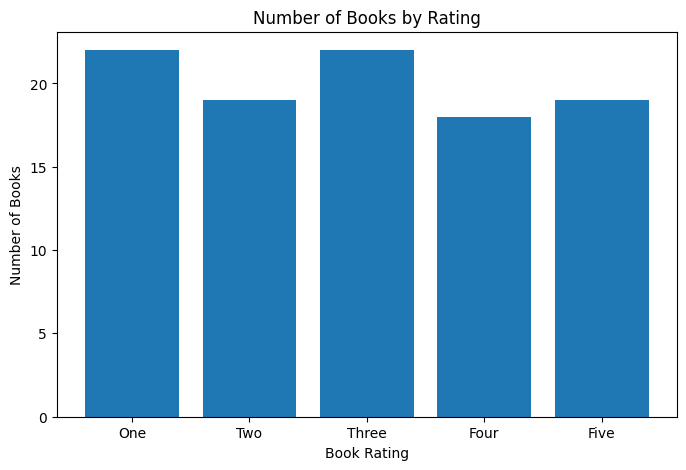

In [6]:

import matplotlib.pyplot as plt

rating_order = [
    "One", "Two", "Three", "Four", "Five"
]

counts = (
    df["Rating"]
    .value_counts()
    .reindex(rating_order, fill_value=0)
)

plt.figure(figsize=(8, 5))
plt.bar(counts.index, counts.values)

plt.title("Number of Books by Rating")
plt.xlabel("Book Rating")
plt.ylabel("Number of Books")

plt.show()


In [7]:

df.to_excel("cleaned_books_data.xlsx", index=False)

files.download("cleaned_books_data.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

!pip install scrapy


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.0/48.0 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 379.8/379.8 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 493.4/493.4 kB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 73.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 283.5/283.5 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.5/107.5 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.6/74.6 kB 6.6 MB/s eta 0:00:00


In [9]:

%%writefile books_spider.py

import scrapy

class BooksSpider(scrapy.Spider):
    name = "books"

    start_urls = [
        "https://books.toscrape.com/"
    ]

    custom_settings = {
        "DOWNLOAD_DELAY": 1,
        "ROBOTSTXT_OBEY": True
    }

    def parse(self, response):

        for book in response.css("article.product_pod"):

            yield {
                "Title": book.css("h3 a::attr(title)").get(),
                "Price": book.css(
                    ".price_color::text"
                ).get(),
                "Rating": book.css(
                    ".star-rating::attr(class)"
                ).get(),
                "Product Link": response.urljoin(
                    book.css("h3 a::attr(href)").get()
                )
            }

        next_page = response.css(
            "li.next a::attr(href)"
        ).get()

        if next_page:
            yield response.follow(
                next_page,
                callback=self.parse
            )


Writing books_spider.py


In [10]:

!scrapy runspider books_spider.py -O books_scrapy.csv

2026-10-18 00:38:15 [scrapy.utils.log] INFO: Scrapy 2.19.0 started (bot: scrapybot)
2026-10-18 00:38:15 [scrapy.utils.log] INFO: Versions:
{'lxml': '6.1.3',
 'libxml2': '2.14.6',
 'cssselect': '1.6.0',
 'parsel': '1.12.1',
 'w3lib': '2.5.0',
 'Twisted': '26.4.0',
 'Python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]',
 'pyOpenSSL': '26.4.0 (OpenSSL 4.0.3 29 Sep 2026)',
 'cryptography': '50.0.2',
 'Platform': 'Linux-6.6.122+-x86_64-with-glibc2.39'}
2026-10-18 00:38:15 [scrapy.crawler] DEBUG: Using AsyncCrawlerProcess
2026-10-18 00:38:15 [asyncio] DEBUG: Using selector: EpollSelector
2026-10-18 00:38:15 [scrapy.addons] INFO: Enabled addons:
[]
2026-10-18 00:38:15 [scrapy.utils.log] DEBUG: Using reactor: twisted.internet.asyncioreactor.AsyncioSelectorReactor
2026-10-18 00:38:15 [scrapy.utils.log] DEBUG: Using asyncio event loop: asyncio.unix_events._UnixSelectorEventLoop
2026-10-18 00:38:15 [scrapy.extensions.telnet] INFO: Telnet Password: 04f4ddccda2a1b1a
2026-10-18 00:38:16 [sc

In [11]:

import pandas as pd

df = pd.read_csv("books_scrapy.csv")

print("Total books:", len(df))
display(df.head())

Total books: 1000


,Title,Price,Rating,Product Link
0,A Light in the Attic,£51.77,star-rating Three,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,£53.74,star-rating One,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,£50.10,star-rating One,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,£47.82,star-rating Four,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,£54.23,star-rating Five,https://books.toscrape.com/catalogue/sapiens-a...


In [12]:

df["Price"] = (
    df["Price"]
    .str.replace("£", "", regex=False)
    .astype(float)
)

df["Rating"] = (
    df["Rating"]
    .str.replace("star-rating ", "", regex=False)
)

df = df.drop_duplicates(subset=["Product Link"])

display(df.head())

,Title,Price,Rating,Product Link
0,A Light in the Attic,51.77,Three,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,https://books.toscrape.com/catalogue/sapiens-a...


In [13]:

from google.colab import files

df.to_excel("scrapy_books_cleaned.xlsx", index=False)

files.download("scrapy_books_cleaned.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>